# Is there a snake? The no-snake gate, before and after training on non-snake photos

Before the app names a species it must decide whether the photo shows a snake at all. In Milestone 3 that
decision was the detector's confidence: a photo was a snake if the detector's best box scored at least 0.102.
The cut-off was fitted to keep 99% of the calibration snakes, but the detector and the segmenter had only ever
seen snake photos, and we never measured how often they see a snake where there is none. At the Milestone 3
review the detector drew snake boxes round a person and round a lion printed on a T-shirt.

This notebook measures that, then fixes it:

1. **Before:** score the Milestone 3 detector (YOLO26n) and segmenter (U-Net) on calibration snakes, validation
   snakes and the non-snake validation photos from notebook 19.
2. **Retrain** both with the Milestone 3 recipe, adding the non-snake training photos: as empty-label background
   images for the detector (10% of its training photos) and with empty masks for the segmenter.
3. **Compare three gates** for both pairs of models: the box alone, the mask alone, and both must agree. Each
   gate's cut-off is fitted on calibration snakes to keep at least 99% of them, as Milestone 3 did. The non-snake
   validation photos pick the gate (the lowest false-snake rate), and the validation snakes check the 99%.

Goal G4 is at most 5% of non-snake test photos called a snake, with at least 99% of validation snakes still
found. The non-snake test photos are not opened here; the full-training notebook (21) scores them once, with the
gate picked here.

A Kaggle GPU session can wait hours in the queue, so everything happens in one session. Every step is a function,
and the steps run twice: first a **smoke pass** on 200 photos of each set with one training epoch, then the **full
pass**. The Kaggle runner executes every cell even after one fails, so that the notebook is always saved with its
outputs. A failure must still stop what comes after it, so the input cells record that they finished, the smoke
pass starts only when they all did, the full pass only when the smoke passed (`SMOKE_PASSED`), and the tables and
pictures at the end only when the full pass finished.

It needs the clean snake photos, the SAM masks and Grounding DINO boxes, the experiment subset, notebook 13's
trained models and notebook 19's non-snake set, all found by name with `kagglehub`. It runs on Kaggle with a GPU
and internet on. The run saved here (kernel `sg-m4-gate`, version 3) took 68 minutes: 5 to read the photos, 1 for the smoke pass and 60 for the full pass. It saves the retrained weights
`M4_detector.pt` and `M4_segmenter.pt`, and the result files under `gate/`, which go to `results/m4/gate/` in the
repo. The smoke pass writes under `smoke/`, with `smoke_` in front of the file names the next notebook looks for.

In [1]:
%pip install -q albumentations==2.0.8 timm==1.0.31 scikit-learn==1.9.1
%pip install -q ultralytics==8.4.202 segmentation-models-pytorch==0.6.0

import hashlib, json, os, shutil, sys, time, warnings
from pathlib import Path
from types import SimpleNamespace

os.environ.update(NO_ALBUMENTATIONS_UPDATE="1", YOLO_VERBOSE="False", HF_HUB_DISABLE_PROGRESS_BARS="1")
warnings.filterwarnings("ignore")

import cv2, kagglehub, matplotlib.pyplot as plt, numpy as np, pandas as pd, torch
from IPython.display import Image as Picture, display
from ultralytics import YOLO

ON_KAGGLE = Path("/kaggle/working").exists()
REPO = Path("/kaggle/working/repo") if ON_KAGGLE else Path("..").resolve()
sys.path.insert(0, str(REPO / "src"))
from serpentguard import data, front_end
from serpentguard.data import build_frame, load_rgb, warm_cache, with_files
from serpentguard.front_end import (GATE_RULES, Segmenter, box_iou, false_snake_rate, fit_gate, gate_calls,
                                    gate_scores, snake_recall)
from serpentguard.metrics import assert_no_test_paths, write_json

SMOKE_PHOTOS, SMOKE_EPOCHS = 200, 1
SEED = 42
NEGATIVE_SHARE = 0.10   # non-snake photos as a share of the detector's training photos
KEEP = front_end.GATE_KEEP
FALSE_SNAKE_GOAL = 0.05
BOX_FLOOR = 0.05        # notebook 13's floor: the boxes in frontend_preds.csv, which full training uses
M3_TAU_SNAKE = 0.102    # Milestone 3's cut-off, results/m3/fe/*/decision_metrics.json
M3_DETECTOR_BATCH = 16  # photos per detector call when Milestone 3 wrote frontend_preds.csv
REPRODUCE = dict(box_agreement=0.99, mask_agreement=0.99, p99_conf_gap=0.03, tau_gap=0.01)
DETECTOR_SHA256 = "099b36bd8271c328b60be8152161f74558a0083ebe4e6fec1f558e7c0951c5b0"  # notebook 17's check
SUBSET_FINGERPRINT = "40196d19a68e"
SHEET_PHOTOS = 20
RECIPE_EPOCHS = {"segmenter": front_end.SEG["epochs"], "detector": front_end.DET["epochs"]}
OUT = Path("/kaggle/working") if ON_KAGGLE else Path("../work/no_snake_gate").resolve()
front_end.TMP = front_end.TMP.resolve()
for folder in (OUT, front_end.TMP):
    folder.mkdir(parents=True, exist_ok=True)
os.chdir(front_end.TMP)  # Ultralytics downloads its starting weights into the working folder
PASSED = set()  # the input cells that finished; the smoke pass starts only when all did
SMOKE_PASSED = FULL_PASSED = False
print(f"{front_end.DEVICE}, {torch.cuda.device_count()} GPU(s), {front_end.WORKERS} CPUs; results go to {OUT}")
print("segmenter recipe:", front_end.SEG, "\ndetector recipe:", front_end.DET)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
cuda, 2 GPU(s), 4 CPUs; results go to /kaggle/working
segmenter recipe: {'epochs': 15, 'batch': 32, 'size': 320, 'lr': 0.001, 'weight_decay': 0.0001, 'aug_strength': 0.25, 'seed': 42} 
detector recipe: {'epochs': 20, 'batch': 32, 'size': 320, 'seed': 42}


## 1. The photos

Three kinds of photos are scored, and each has one job:

- **Calibration snakes** (7,999 training photos whose photographers are in no training set): the gates' cut-offs
  are fitted here, as Milestone 3 fitted its cut-off.
- **Validation snakes** (17,151): check that the gate still finds at least 99% of real snakes.
- **Non-snake validation photos** (600 from notebook 19): count the false snakes and pick the gate.

The non-snake set was split by photographer, so no photographer of a validation photo has a training photo.
Its test split is never read in this notebook. The snake photos are never shown, because many are not openly
licensed; the non-snake photos are all CC BY or CC0 and are credited where they are shown.

The retraining uses notebook 13's photos: the experiment subset's photos with a usable SAM mask for the
segmenter, and those with a Grounding DINO box for the detector, plus the 1,799 non-snake training photos.

In [2]:
def dataset(slug):
    return Path(kagglehub.dataset_download(f"puneetbajajiitm/{slug}"))


def kernel_output(handle):
    return Path(kagglehub.notebook_output_download(handle))


DATA = dataset("serpentguard-indian-snakes-clean")
MASKS = dataset("serpentguard-sam-masks")
ids = {"obs_id": str, "photo_id": str, "observer_id": str}
metadata = pd.read_csv(DATA / "metadata.csv", dtype=ids, low_memory=False)
classes = pd.read_csv(DATA / "classes.csv")
subset = pd.read_csv(dataset("serpentguard-m3-subset") / "subset.csv", dtype=ids)
mask_stats = pd.read_csv(MASKS / "mask_stats.csv")
fingerprint = hashlib.sha256("\n".join(sorted(subset["path"])).encode()).hexdigest()
assert fingerprint.startswith(SUBSET_FINGERPRINT), "this is not the experiment subset"

NEG = next(kernel_output("puneetbajajiitm/sg-m4-non-snake").rglob("manifest.csv")).parent
manifest = pd.read_csv(NEG / "manifest.csv")
manifest["image_file"] = [str(NEG / f) for f in manifest["file"]]
neg_train = manifest[manifest["split"] == "train"].rename(columns={"file": "path"})
neg_val = manifest[manifest["split"] == "val"].rename(columns={"file": "path"})
assert len(neg_train) and len(neg_val) and not set(neg_train["owner"]) & set(neg_val["owner"])
categories = neg_val.set_index("path")["category"]


def snake_rows(rows):
    return rows.assign(is_snake=True, image_file=[str(DATA / "data" / p) for p in rows["path"]])


train = metadata[metadata["split"] == "train"]
frames = {"calibration": snake_rows(data.calibration_set(train, subset)),
          "snake_val": snake_rows(metadata[metadata["split"] == "val"]),
          "nonsnake_val": neg_val.assign(is_snake=False)}
for name in ("calibration", "snake_val"):
    assert_no_test_paths(frames[name])

train_rows = train[train["path"].isin(subset["path"])]
seg_frame = build_frame(train_rows, classes, ["train"], mask_stats, masks_root=MASKS)
seg_frame = with_files(seg_frame[seg_frame["mask_valid"]], DATA).reset_index(drop=True)
det_frame = train_rows[["path"]].merge(mask_stats[["path", "snake_boxes"]], on="path", how="left",
                                       validate="one_to_one")
parse = lambda text: json.loads(text) if isinstance(text, str) and text.strip() else []
det_frame["snake_boxes"] = det_frame["snake_boxes"].map(parse)
det_frame = det_frame[det_frame["snake_boxes"].map(len) > 0].reset_index(drop=True)
det_frame["image_file"] = [str(DATA / "data" / p) for p in det_frame["path"]]
print("photos read into the page cache:",
      warm_cache([f for frame in frames.values() for f in frame["image_file"]]
                 + list(seg_frame["image_file"]) + list(seg_frame["mask_file"]) + list(det_frame["image_file"])
                 + list(neg_train["image_file"])))
print({name: len(frame) for name, frame in frames.items()}, "photos to score; training photos: segmenter",
      f"{len(seg_frame):,}, detector {len(det_frame):,}, non-snake {len(neg_train):,}")
PASSED.add("inputs")

photos read into the page cache: {'files': 51549, 'missing': 0, 'seconds': 328.44522230199993, 'mb': 5447.811721}
{'calibration': 7999, 'snake_val': 17151, 'nonsnake_val': 600} photos to score; training photos: segmenter 10,499, detector 13,501, non-snake 1,799


## 2. The Milestone 3 models, and how well they reproduce Milestone 3's file

The weights come from notebook 13's saved run (kernel `sg-m3-frontends`), the same files that made
`frontend_preds.csv`; the detector's fingerprint is checked as in notebook 17. For every photo we record two
scores:

- `box_conf`: the confidence of the detector's best snake box. Every box down to 0.001 is kept here, so a cut-off
  under notebook 13's 0.05 floor could still be fitted; a photo with no box at all has none.
- `mask_area`: the share of the photo the segmenter paints as snake. This is the raw mask, before the cleanup
  that later notebooks apply. The cleanup empties every mask under 1.5% of the photo, which already removes about
  12% of the calibration snakes' masks, so a cleaned mask could never keep 99% of them.

**Why the reproduction check exists.** The "before" numbers only mean something if these are Milestone 3's
models, read the way Milestone 3 read them. So every pass compares its Milestone 3 boxes with
`frontend_preds.csv` and refits Milestone 3's cut-off.

**The drift we found.** In the first smoke run, 398 of 400 snake photos reproduced Milestone 3's confidence to the
file's four decimals, and two validation photos moved: 0.7887 became 0.7639 and 0.8667 became 0.8850, with box
corners up to 10 pixels apart. The cause is Milestone 3's own run, not this one. Milestone 3 called the detector 16
photos at a time with Ultralytics' default `rect=True`, and when all 16 photos of a call share one shape, Ultralytics
pads them less, so the detector sees a slightly different picture. Our code passes `rect=False`, which pads every
photo alike. Both drifting photos sat in such a 16-photo call, and no other photo did. On the laptop, the same
detector on 24 photos of one shape moved by a median 0.013 between the two settings, and by nothing on a batch of
mixed shapes. Rebuilding Milestone 3's calls from the row order of its file, 144 of the 17,151 validation photos
(0.84%) and none of the calibration photos were affected. The check therefore asks for what that leaves:

- at least 99% of photos have a box at 0.05 or above in both runs, or in neither;
- the 99th percentile of the confidence difference is at most 0.03;
- at least 99% of the photos with a cleaned mask in Milestone 3's file have a raw mask here;
- on the full calibration set, the refitted cut-off is within 0.01 of Milestone 3's 0.102.

The measured numbers, split into photos inside and outside Milestone 3's one-shape calls, are printed and saved in
`gate/m3_reproduction.json`.

In [3]:
FRONT = kernel_output("puneetbajajiitm/sg-m3-frontends")
M3_DETECTOR = next(FRONT.rglob("D1/yolo26n-ft/detector.pt"))
M3_UNET = next(FRONT.rglob("S1/unet/segmenter.pt"))
sha = hashlib.sha256(M3_DETECTOR.read_bytes()).hexdigest()
assert sha == DETECTOR_SHA256, f"the Milestone 3 detector differs from notebook 17's: {sha}"
m3_detector, m3_segmenter = YOLO(str(M3_DETECTOR)), Segmenter("unet", M3_UNET.parent)
m3_preds = pd.read_csv(next(FRONT.rglob("frontend_preds.csv")), keep_default_na=False)
dims = metadata.set_index("path").reindex(m3_preds["path"])
shapes = dims["height"].astype(str) + "x" + dims["width"].astype(str)
one_shape = shapes.groupby(np.arange(len(m3_preds)) // M3_DETECTOR_BATCH).transform("nunique").eq(1).to_numpy()
m3_one_shape = set(m3_preds.loc[one_shape, "path"])
m3_preds = m3_preds.set_index("path")
print(f"{len(m3_preds):,} rows in Milestone 3's file; {len(m3_one_shape):,} photos sat in a one-shape call of "
      f"{M3_DETECTOR_BATCH}: validation {frames['snake_val']['path'].isin(m3_one_shape).sum():,}, "
      f"calibration {frames['calibration']['path'].isin(m3_one_shape).sum():,}")
PASSED.add("M3 models")

39,526 rows in Milestone 3's file; 144 photos sat in a one-shape call of 16: validation 144, calibration 0


## 3. The steps of one pass

Each step is a function, so that the smoke pass and the full pass run exactly the same code.

**Scoring.** Both scores for every photo of the three sets, saved as `scores/<models>_<set>.csv`.

In [4]:
def limited(frame, limit):
    return frame if limit is None or len(frame) <= limit else frame.sample(limit, random_state=SEED)


def score_all(name, detector, segmenter, sets, out):
    """gate_scores on every set, saved as scores/<name>_<set>.csv."""
    (out / "scores").mkdir(parents=True, exist_ok=True)
    scores = {}
    for set_name, frame in sets.items():
        started = time.perf_counter()
        scores[set_name] = gate_scores(frame, detector, segmenter)
        saved = scores[set_name].assign(box=scores[set_name]["box"].map(
            lambda b: "" if b is None else json.dumps([round(v, 2) for v in b])))
        saved.to_csv(out / "scores" / f"{name}_{set_name}.csv", index=False)
        print(f"{name} {set_name}: {len(frame):,} photos in {(time.perf_counter() - started) / 60:.1f} min")
    return scores

**The reproduction check** described in section 2.

In [5]:
def check_m3(m3, out, full):
    snakes = pd.concat([m3["calibration"], m3["snake_val"]], ignore_index=True)
    old = m3_preds.reindex(snakes["path"])
    assert old["box"].notna().all(), "a scored snake photo has no row in Milestone 3's file"
    had = old["box_conf"].ne("").to_numpy()
    now = snakes["box_conf"].to_numpy(float)
    has = np.nan_to_num(now, nan=0.0) >= BOX_FLOOR
    both = had & has
    gap = np.abs(now[both] - pd.to_numeric(old["box_conf"][both]).to_numpy(float))
    inside = snakes["path"].isin(m3_one_shape).to_numpy()[both]
    cleaned = old["mask_file"].ne("").to_numpy()
    tau = fit_gate(m3["calibration"], "box", KEEP)["box_conf"]

    def spread(values):
        if not len(values):
            return {"photos": 0}
        return {"photos": int(len(values)), "median": float(np.median(values)),
                "p95": float(np.percentile(values, 95)), "p99": float(np.percentile(values, 99)),
                "max": float(values.max()), "within_0_001": float((values <= 0.001).mean())}

    report = {"photos": len(snakes), "box_agreement": float((had == has).mean()),
              "box_then_not_now": int((had & ~has).sum()), "box_now_not_then": int((~had & has).sum()),
              "conf_gap": spread(gap), "conf_gap_outside_one_shape_calls": spread(gap[~inside]),
              "conf_gap_inside_one_shape_calls": spread(gap[inside]),
              "mask_agreement": float((snakes["mask_area"].to_numpy()[cleaned] > 0).mean()) if cleaned.any() else 1.0,
              "tau_snake_refit": tau, "tau_snake_m3": M3_TAU_SNAKE, "full_calibration": full,
              "tolerances": REPRODUCE}
    write_json(out / "gate" / "m3_reproduction.json", report)
    print(f"box at {BOX_FLOOR} in both runs or neither: {report['box_agreement']:.2%} of {len(snakes):,} snake "
          f"photos; confidence difference median {report['conf_gap'].get('median', 0):.5f}, 99th percentile "
          f"{report['conf_gap'].get('p99', 0):.5f}, largest {report['conf_gap'].get('max', 0):.4f}; outside "
          f"Milestone 3's one-shape calls the largest is {report['conf_gap_outside_one_shape_calls'].get('max', 0):.5f}"
          f"; cut-off refitted {tau:.4f} against Milestone 3's {M3_TAU_SNAKE}")
    assert report["box_agreement"] >= REPRODUCE["box_agreement"], "box or no box disagrees too often"
    assert report["conf_gap"].get("p99", 0) <= REPRODUCE["p99_conf_gap"], "the confidences moved too much"
    assert report["mask_agreement"] >= REPRODUCE["mask_agreement"], "Milestone 3's masks are not reproduced"
    if full:
        assert abs(tau - M3_TAU_SNAKE) <= REPRODUCE["tau_gap"], f"the refitted cut-off is {tau}, not {M3_TAU_SNAKE}"
    return report

**Retraining.** The recipe is notebook 13's, unchanged: the same experiment-subset photos, SAM masks for the
segmenter and Grounding DINO boxes for the detector, the same settings and seeds, starting again from the same
ImageNet and COCO weights. The only change is the non-snake training photos:

- **Detector:** non-snake photos with an empty label file, which YOLO treats as background images. They make up 10%
  of its training photos (a seeded random draw from the 1,799), the share Ultralytics suggests for backgrounds.
- **Segmenter:** all 1,799 non-snake photos, each with an empty mask as its target, so the loss pushes every
  pixel toward "not snake".

A finished model is not retrained when the cell runs again.

In [6]:
def retrain(out, limit, epochs, prefix):
    seg_rows, det_rows = limited(seg_frame, limit), limited(det_frame, limit)
    seg_negatives = limited(neg_train, limit)[["path", "image_file"]]
    wanted = min(len(neg_train), round(NEGATIVE_SHARE / (1 - NEGATIVE_SHARE) * len(det_rows)))
    det_negatives = neg_train.sample(wanted, random_state=SEED)[["path", "image_file"]]
    print(f"segmenter: {len(seg_rows):,} snake photos with masks + {len(seg_negatives):,} non-snake photos; "
          f"detector: {len(det_rows):,} snake photos with boxes + {len(det_negatives):,} non-snake photos "
          f"({len(det_negatives) / (len(det_rows) + len(det_negatives)):.1%})")
    folder = out / "m4_front_end"
    front_end.SEG["epochs"] = epochs or RECIPE_EPOCHS["segmenter"]
    det_settings = dict(front_end.DET, epochs=epochs or RECIPE_EPOCHS["detector"])
    if not (folder / "segmenter/run.json").exists():
        front_end.train_segmenter("unet", folder / "segmenter", seg_rows, negatives=seg_negatives)
    shutil.copy(folder / "segmenter/segmenter.pt", folder / f"{prefix}M4_segmenter.pt")
    if not (folder / "detector/run.json").exists():
        front_end.train_yolo(f"yolo26n-m4-{prefix or 'full'}", "yolo26n.pt", det_rows, folder / "detector",
                             det_settings, True, f"{prefix}M4_detector.pt", negatives=det_negatives)
    runs = {kind: json.loads((folder / kind / "run.json").read_text()) for kind in ("segmenter", "detector")}
    print(f"segmenter: {runs['segmenter']['train_photos']:,} + {runs['segmenter']['negative_photos']:,} non-snake "
          f"photos, {runs['segmenter']['seconds'] / 60:.0f} min; detector: {runs['detector']['train_photos']:,} "
          f"photos of which {runs['detector']['negative_photos']:,} non-snake, {runs['detector']['seconds'] / 60:.0f} min")
    detector = YOLO(str(folder / "detector" / f"{prefix}M4_detector.pt"))
    return detector, Segmenter("unet", folder / "segmenter"), runs

**The three gates.** For each pair of models and each gate, the cut-offs are fitted on the calibration snakes
only:

- **box:** the detector's best box must reach a cut-off that 99% of calibration snakes reach, exactly as
  Milestone 3 fitted 0.102 (`decide.fit_snake_threshold`). A photo with no box is never a snake.
- **mask:** the same, on the share of the photo the segmenter paints. A photo with nothing painted is never a snake.
- **both:** a photo is a snake only if both reach their cut-offs. The two cut-offs are set so that each keeps the
  same number of calibration snakes, the fewest that still lets 99% of them pass both. Each cut-off is then looser
  than when it stands alone, because a snake can now be lost through either score.

Each gate is then counted on the validation photos: the share of non-snake photos called a snake (the false-snake
rate), and the share of snakes found (recall). The non-snake validation photos pick the gate for the retrained
models: the lowest false-snake rate, then the higher recall. `gate.json` holds the pick for notebook 21.

In [7]:
def compare_gates(m3, m4, out, limit, epochs, prefix):
    rows, cuts = [], {}
    for name, scores in (("M3", m3), ("M4", m4)):
        for rule in GATE_RULES:
            cut = fit_gate(scores["calibration"], rule, KEEP)
            cuts[name, rule] = cut
            rows.append({"front_end": name, "rule": rule,
                         "thresholds": json.dumps({k: round(v, 6) for k, v in cut.items()}),
                         "recall_calibration": snake_recall(scores["calibration"], rule, cut),
                         "fpr_nonsnake_val": false_snake_rate(scores["nonsnake_val"], rule, cut),
                         "recall_snake_val": snake_recall(scores["snake_val"], rule, cut),
                         "n_calibration": len(scores["calibration"]), "n_nonsnake_val": len(scores["nonsnake_val"]),
                         "n_snake_val": len(scores["snake_val"])})
    gates = pd.DataFrame(rows)
    gates["meets_g4_on_val"] = gates["fpr_nonsnake_val"].le(FALSE_SNAKE_GOAL) & gates["recall_snake_val"].ge(KEEP)
    order = {rule: i for i, rule in enumerate(GATE_RULES)}
    pick = (gates[gates["front_end"] == "M4"].assign(order=lambda g: g["rule"].map(order))
            .sort_values(["fpr_nonsnake_val", "recall_snake_val", "order"], ascending=[True, False, True]).iloc[0])
    gates["picked"] = gates["front_end"].eq("M4") & gates["rule"].eq(pick["rule"])
    gates.to_csv(out / "gate" / "gates.csv", index=False)
    gate = {"kernel": "puneetbajajiitm/sg-m4-gate", "detector": f"{prefix}M4_detector.pt",
            "segmenter": f"{prefix}M4_segmenter.pt", "rule": pick["rule"], "thresholds": cuts["M4", pick["rule"]],
            "keep": KEEP, "fpr_nonsnake_val": pick["fpr_nonsnake_val"], "recall_snake_val": pick["recall_snake_val"],
            "limit": limit, "epochs": epochs}
    write_json(out / "gate" / f"{prefix}gate.json", gate)
    print(f"picked for the app: {pick['rule']} with {gate['thresholds']}: {pick['fpr_nonsnake_val']:.1%} of non-snake "
          f"val photos called a snake, {pick['recall_snake_val']:.2%} of val snakes found")
    return gates, cuts, pick["rule"]

**Which photos still fool it.** The false-snake rate by kind of non-snake photo, for both pairs of models at their
own cut-offs for the picked gate. People and printed T-shirts are the review's case. The lookalikes (eels, glass
lizards, caecilians, earthworms) are the hardest, and training "no snake" on them could cost snakes that look like
them, so the second table gives the recall on those snakes: sea snakes and sea kraits and other water snakes (like
eels), blind snakes and shieldtails (like earthworms and caecilians), and vine snakes and bronzebacks (slender,
like glass lizards).

In [8]:
LOOKALIKE_GROUPS = {
    "sea snakes and sea kraits": lambda m: m["genus"].isin(["Hydrophis", "Laticauda"]),
    "other water snakes": lambda m: m["family"].isin(["Homalopsidae", "Acrochordidae"]),
    "blind snakes and shieldtails": lambda m: m["family"].isin(["Typhlopidae", "Uropeltidae"]),
    "vine snakes and bronzebacks": lambda m: m["genus"].isin(["Ahaetulla", "Dendrelaphis"]),
}


def breakdowns(m3, m4, cuts, rule, sets, out):
    by_category = {}
    for name, scores in (("M3", m3), ("M4", m4)):
        called = gate_calls(scores["nonsnake_val"], rule, cuts[name, rule])
        by_category[name] = pd.Series(called, index=categories.reindex(scores["nonsnake_val"]["path"]).to_numpy())
    fpr_by_category = pd.DataFrame({f"{name} called a snake": calls.groupby(level=0).mean()
                                    for name, calls in by_category.items()})
    fpr_by_category["photos"] = by_category["M4"].groupby(level=0).size()
    fpr_by_category.to_csv(out / "gate" / "fpr_by_category.csv", index_label="category")

    val_taxa = sets["snake_val"].set_index("path")[["genus", "family"]]
    groups = {group: rows_of(val_taxa).to_numpy() for group, rows_of in LOOKALIKE_GROUPS.items()}
    groups["all other snakes"] = ~np.any(list(groups.values()), axis=0)
    groups["all val snakes"] = np.ones(len(val_taxa), dtype=bool)
    recall_rows = []
    for group, members in groups.items():
        row = {"group": group, "photos": int(members.sum())}
        for name, scores in (("M3", m3), ("M4", m4)):
            assert scores["snake_val"]["path"].tolist() == val_taxa.index.tolist()
            for each in GATE_RULES:
                calls = gate_calls(scores["snake_val"], each, cuts[name, each])
                row[f"{name} {each}"] = float(calls[members].mean()) if members.any() else np.nan
        recall_rows.append(row)
    lookalike_recall = pd.DataFrame(recall_rows).set_index("group")
    lookalike_recall.to_csv(out / "gate" / "lookalike_recall.csv")
    return fpr_by_category, lookalike_recall

**Do the new boxes match the old ones?** Full training (notebook 21) crops every photo to the Milestone 3
detector's box, while the app will crop to the retrained detector's box. If the two boxes differ much, the
classifier will see a different crop in the app than in training. On the validation snakes where both detectors
find a box at notebook 13's 0.05 floor, we measure how well the two best boxes overlap (IoU: the shared area over
the combined area, 1 for identical boxes).

In [9]:
def box_agreement(m3, m4, out):
    pair = pd.DataFrame({"m3_box": m3["snake_val"]["box"], "m3_conf": m3["snake_val"]["box_conf"],
                         "m4_box": m4["snake_val"]["box"], "m4_conf": m4["snake_val"]["box_conf"]})
    both_found = pair["m3_conf"].ge(BOX_FLOOR) & pair["m4_conf"].ge(BOX_FLOOR)
    ious = np.array([box_iou(a, b) for a, b in pair.loc[both_found, ["m3_box", "m4_box"]].itertuples(index=False)])
    agreement = {"photos": int(both_found.sum()), "of_val_snakes": len(pair),
                 "mean_iou": float(ious.mean()) if len(ious) else None,
                 "median_iou": float(np.median(ious)) if len(ious) else None,
                 "share_iou_at_least_0_5": float((ious >= 0.5).mean()) if len(ious) else None,
                 "share_iou_at_least_0_8": float((ious >= 0.8).mean()) if len(ious) else None, "box_floor": BOX_FLOOR}
    write_json(out / "gate" / "box_agreement.json", agreement)
    return agreement, ious

**Reading the results back.** Every number came out of a bulk run, so it is checked against things that did not
produce it:

1. Every score table has one row per photo of its set, in order, with no photo twice; `mask_area` is never empty and
   lies between 0 and 1; a box and its confidence are always both there or both missing; the saved file has no
   `nan`, `None` or `error` in it.
2. `gates.csv` has six rows (two front ends times three gates) and no empty value.
3. The non-snake test split was never read, and no snake photo comes from a test split.
4. A negative control: the Milestone 3 models never saw a non-snake photo, so their false-snake rate should be
   above the retrained models' for the same gate. This is printed, not asserted: if it fails, the reason is given
   with the results.

Then twenty non-snake validation photos are drawn with the retrained detector's best box (red) and segmenter's mask
(green), to be looked at by eye: the ten it finds most snake-like and ten at random.

In [10]:
def read_back(m3, m4, gates, sets, out):
    for name, scores in (("M3", m3), ("M4", m4)):
        for set_name, frame in sets.items():
            table = scores[set_name]
            assert table["path"].tolist() == frame["path"].tolist() and table["path"].is_unique, (name, set_name)
            assert table["mask_area"].between(0, 1).all(), (name, set_name)
            assert table["box"].isna().equals(table["box_conf"].isna()), (name, set_name)
            saved = pd.read_csv(out / "scores" / f"{name}_{set_name}.csv", keep_default_na=False)
            assert len(saved) == len(frame) and not saved.isin(["nan", "None", "error"]).any().any(), (name, set_name)
    assert len(gates) == 2 * len(GATE_RULES) and not gates.isna().any().any(), "gates.csv has a gap"
    assert not gates.astype(str).isin(["", "nan", "None"]).any().any()
    assert set(sets["nonsnake_val"]["split"]) == {"val"} and set(neg_train["split"]) == {"train"}
    for name in ("calibration", "snake_val"):
        assert not sets[name]["split"].isin(["test", "test_extra"]).any()
    control = gates.pivot(index="rule", columns="front_end", values="fpr_nonsnake_val")
    control["M3 above M4"] = control["M3"] > control["M4"]
    print("negative control (the Milestone 3 rate should be above the retrained one):")
    print(control.round(4).to_string())
    print("photos with no box at all:",
          {f"{n} {s}": int(t[s]["box_conf"].isna().sum()) for n, t in (("M3", m3), ("M4", m4)) for s in sets})
    return control


def draw_sheet(m4, segmenter, cut, rule, out):
    nonsnake = m4["nonsnake_val"].assign(category=categories.reindex(m4["nonsnake_val"]["path"]).to_numpy())
    top = nonsnake.sort_values("box_conf", ascending=False).head(SHEET_PHOTOS // 2)
    rest = nonsnake.drop(top.index)
    shown = pd.concat([top, rest.sample(min(SHEET_PHOTOS - len(top), len(rest)), random_state=SEED)])
    called = gate_calls(shown, rule, cut)
    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, row, is_called) in enumerate(zip(axes.flat, shown.itertuples(), called), start=1):
        rgb = load_rgb(str(NEG / row.path))
        mask = segmenter.masks([rgb])[0] == 1
        shade = rgb.copy()
        shade[mask] = (0.5 * shade[mask] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
        ax.imshow(shade)
        if row.box is not None:
            x1, y1, x2, y2 = row.box
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
        ax.set_title(f"{i}. {row.category}: box {row.box_conf:.2f}, mask {row.mask_area:.3f}\n"
                     f"{'called a snake' if is_called else 'no snake'}", fontsize=10)
    plt.tight_layout()
    (out / "checks").mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "checks" / "nonsnake_val_sheet.png", dpi=60)
    plt.close(fig)
    credits = manifest.set_index("file").loc[shown["path"], ["owner", "licence", "url", "category"]]
    return credits.assign(photo=range(1, len(credits) + 1)).set_index("photo")

### One pass

The steps in order. The smoke pass and the full pass differ only in the number of photos (the smoke draws 200 of
each set, seed 42), the epochs, and where they write.

In [11]:
def run_pass(name, limit, epochs):
    started = time.perf_counter()
    full = limit is None
    out, prefix = (OUT, "") if full else (OUT / "smoke", "smoke_")
    (out / "gate").mkdir(parents=True, exist_ok=True)
    sets = {set_name: limited(frame, limit) for set_name, frame in frames.items()}
    print(f"{name} pass:", {set_name: len(frame) for set_name, frame in sets.items()}, "photos to score")
    m3 = score_all("M3", m3_detector, m3_segmenter, sets, out)
    reproduction = check_m3(m3, out, full)
    detector, segmenter, runs = retrain(out, limit, epochs, prefix)
    m4 = score_all("M4", detector, segmenter, sets, out)
    gates, cuts, rule = compare_gates(m3, m4, out, limit, epochs, prefix)
    fpr_by_category, lookalike_recall = breakdowns(m3, m4, cuts, rule, sets, out)
    agreement, ious = box_agreement(m3, m4, out)
    control = read_back(m3, m4, gates, sets, out)
    credits = draw_sheet(m4, segmenter, cuts["M4", rule], rule, out)
    minutes = (time.perf_counter() - started) / 60
    print(f"{name} pass: every step ran, in {minutes:.0f} min")
    return SimpleNamespace(out=out, m3=m3, m4=m4, reproduction=reproduction, runs=runs, gates=gates, cuts=cuts,
                           rule=rule, fpr_by_category=fpr_by_category, lookalike_recall=lookalike_recall,
                           agreement=agreement, ious=ious, control=control, credits=credits, minutes=minutes)

## 4. The smoke pass

Every step on 200 photos of each set, with one training epoch for each model. It starts only if the input cells
finished, and the full pass starts only if the smoke finished, so a failure here stops the session's GPU work a few
minutes in. The cut-off refit is only compared with 0.102 on the full calibration set.

In [12]:
assert {"inputs", "M3 models"} <= PASSED, f"input cells that did not finish: {sorted({'inputs', 'M3 models'} - PASSED)}"
smoke = run_pass("smoke", SMOKE_PHOTOS, SMOKE_EPOCHS)
SMOKE_PASSED = True
smoke.gates.drop(columns=["n_calibration", "n_nonsnake_val", "n_snake_val"]).round(4)

smoke pass: {'calibration': 200, 'snake_val': 200, 'nonsnake_val': 200} photos to score
M3 calibration: 200 photos in 0.1 min
M3 snake_val: 200 photos in 0.0 min


M3 nonsnake_val: 200 photos in 0.0 min
box at 0.05 in both runs or neither: 100.00% of 400 snake photos; confidence difference median 0.00003, 99th percentile 0.00005, largest 0.0248; outside Milestone 3's one-shape calls the largest is 0.00005; cut-off refitted 0.0962 against Milestone 3's 0.102
segmenter: 200 snake photos with masks + 200 non-snake photos; detector: 200 snake photos with boxes + 22 non-snake photos (9.9%)
unet epoch 1/1: loss 1.5302, 19 s
yolo26n-m4-smoke_: 222 photos, 1 min
segmenter: 200 + 200 non-snake photos, 0 min; detector: 222 photos of which 22 non-snake, 1 min
M4 calibration: 200 photos in 0.0 min
M4 snake_val: 200 photos in 0.0 min
M4 nonsnake_val: 200 photos in 0.0 min
picked for the app: mask with {'mask_area': 0.61096}: 92.5% of non-snake val photos called a snake, 99.00% of val snakes found
negative control (the Milestone 3 rate should be above the retrained one):
front_end     M3     M4  M3 above M4
rule                                
both       0.960

,front_end,rule,thresholds,recall_calibration,fpr_nonsnake_val,recall_snake_val,meets_g4_on_val,picked
0,M3,box,"{""box_conf"": 0.096243}",0.99,0.955,0.985,False,False
1,M3,mask,"{""mask_area"": 0.008048}",0.99,0.980,0.975,False,False
2,M3,both,"{""box_conf"": 0.086795, ""mask_area"": 0.008027}",0.99,0.960,0.965,False,False
3,M4,box,"{""box_conf"": 0.013397}",0.99,1.000,1.000,False,False
4,M4,mask,"{""mask_area"": 0.61096}",0.99,0.925,0.990,False,True
5,M4,both,"{""box_conf"": 0.011358, ""mask_area"": 0.601211}",0.99,0.935,0.990,False,False


## 5. The full pass

In [13]:
assert SMOKE_PASSED, "the smoke pass did not finish, so the full pass does not start"
full = run_pass("full", None, None)
FULL_PASSED = True

full pass: {'calibration': 7999, 'snake_val': 17151, 'nonsnake_val': 600} photos to score
M3 calibration: 7,999 photos in 1.6 min
M3 snake_val: 17,151 photos in 3.4 min
M3 nonsnake_val: 600 photos in 0.1 min
box at 0.05 in both runs or neither: 100.00% of 25,150 snake photos; confidence difference median 0.00003, 99th percentile 0.00005, largest 0.4735; outside Milestone 3's one-shape calls the largest is 0.00005; cut-off refitted 0.1020 against Milestone 3's 0.102
segmenter: 10,499 snake photos with masks + 1,799 non-snake photos; detector: 13,501 snake photos with boxes + 1,500 non-snake photos (10.0%)
unet epoch 1/15: loss 0.8154, 124 s
unet epoch 2/15: loss 0.4936, 124 s
unet epoch 3/15: loss 0.4764, 124 s
unet epoch 4/15: loss 0.4575, 123 s
unet epoch 5/15: loss 0.4242, 123 s
unet epoch 6/15: loss 0.4015, 123 s
unet epoch 7/15: loss 0.3822, 123 s
unet epoch 8/15: loss 0.3437, 123 s
unet epoch 9/15: loss 0.3259, 123 s
unet epoch 10/15: loss 0.3025, 123 s
unet epoch 11/15: loss 0.29

## 6. Results of the full pass

**The reproduction check.**

In [14]:
assert FULL_PASSED, "the full pass did not finish"
pd.json_normalize(full.reproduction).T.rename(columns={0: "Milestone 3 reproduced"})

,Milestone 3 reproduced
photos,25150
box_agreement,1.0
box_then_not_now,0
box_now_not_then,0
mask_agreement,1.0
tau_snake_refit,0.101952
tau_snake_m3,0.102
full_calibration,True
conf_gap.photos,25141
conf_gap.median,0.000025


**The retrained segmenter's training loss.**

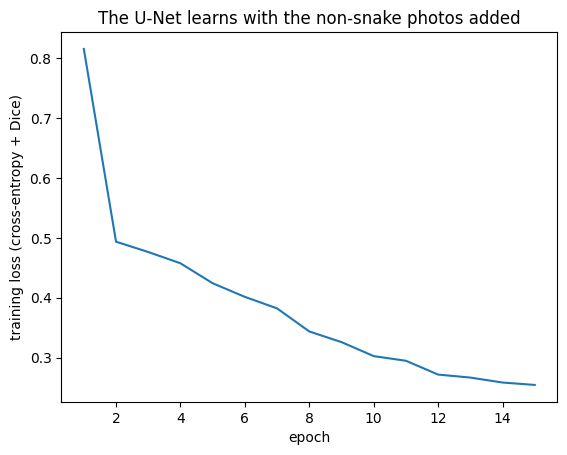

In [15]:
assert FULL_PASSED, "the full pass did not finish"
plt.plot(range(1, len(full.runs["segmenter"]["epoch_loss"]) + 1), full.runs["segmenter"]["epoch_loss"])
plt.xlabel("epoch"); plt.ylabel("training loss (cross-entropy + Dice)")
plt.title("The U-Net learns with the non-snake photos added"); plt.show()

**The three gates**, for both pairs of models.

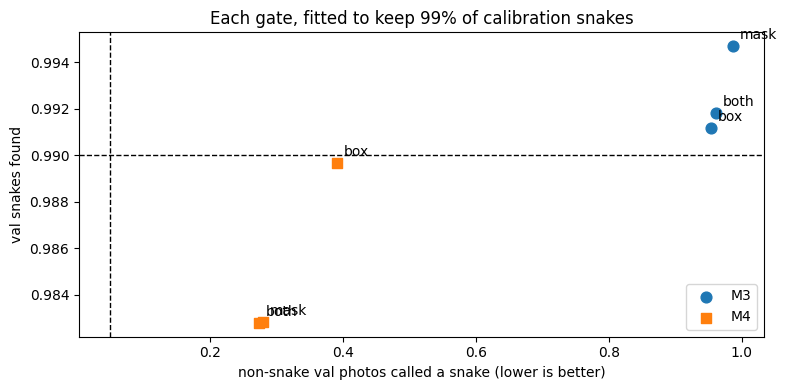

,front_end,rule,thresholds,recall_calibration,fpr_nonsnake_val,recall_snake_val,meets_g4_on_val,picked
0,M3,box,"{""box_conf"": 0.101952}",0.9901,0.9533,0.9912,False,False
1,M3,mask,"{""mask_area"": 0.005922}",0.9901,0.9867,0.9947,False,False
2,M3,both,"{""box_conf"": 0.087618, ""mask_area"": 0.00437}",0.9901,0.9617,0.9918,False,False
3,M4,box,"{""box_conf"": 0.085111}",0.9901,0.3917,0.9897,False,False
4,M4,mask,"{""mask_area"": 4.8e-05}",0.9797,0.2800,0.9829,False,False
5,M4,both,"{""box_conf"": 0.004993, ""mask_area"": 4.8e-05}",0.9797,0.2733,0.9828,False,True


In [16]:
assert FULL_PASSED, "the full pass did not finish"
fig, ax = plt.subplots(figsize=(8, 4))
for name, marker in (("M3", "o"), ("M4", "s")):
    part = full.gates[full.gates["front_end"] == name]
    ax.scatter(part["fpr_nonsnake_val"], part["recall_snake_val"], marker=marker, s=60, label=name)
    for _, row in part.iterrows():
        ax.annotate(row["rule"], (row["fpr_nonsnake_val"], row["recall_snake_val"]), xytext=(5, 5),
                    textcoords="offset points")
ax.axvline(FALSE_SNAKE_GOAL, color="k", ls="--", lw=1); ax.axhline(KEEP, color="k", ls="--", lw=1)
ax.set_xlabel("non-snake val photos called a snake (lower is better)")
ax.set_ylabel("val snakes found")
ax.set_title("Each gate, fitted to keep 99% of calibration snakes"); ax.legend(); plt.tight_layout(); plt.show()
full.gates.drop(columns=["n_calibration", "n_nonsnake_val", "n_snake_val"]).round(4)

**The false-snake rate by kind of photo**, at the picked gate.

In [17]:
assert FULL_PASSED, "the full pass did not finish"
print(f"gate: {full.rule}, each pair at its own cut-offs")
full.fpr_by_category.round(3)

gate: both, each pair at its own cut-offs


,M3 called a snake,M4 called a snake,photos
caecilian,1.000,1.000,20
cat,0.975,0.075,40
dog,0.950,0.050,40
earthworm,1.000,1.000,20
eel,0.975,0.950,40
hand_arm,0.983,0.067,60
legless_lizard,1.000,1.000,20
other_animal,0.983,0.417,60
person,0.928,0.083,180
rope_hose_belt,0.967,0.250,60


**The share of validation snakes found, by group**, for each front end and gate.

In [18]:
assert FULL_PASSED, "the full pass did not finish"
full.lookalike_recall.round(3)

,photos,M3 box,M3 mask,M3 both,M4 box,M4 mask,M4 both
group,,,,,,,
sea snakes and sea kraits,715,0.999,0.987,0.992,0.993,0.969,0.969
other water snakes,318,0.994,0.994,0.991,0.991,0.991,0.991
blind snakes and shieldtails,1763,0.997,0.993,0.996,0.995,0.974,0.974
vine snakes and bronzebacks,1959,0.989,0.995,0.991,0.989,0.987,0.987
all other snakes,12396,0.990,0.995,0.991,0.989,0.984,0.984
all val snakes,17151,0.991,0.995,0.992,0.990,0.983,0.983


**Box agreement** between the Milestone 3 and the retrained detector.

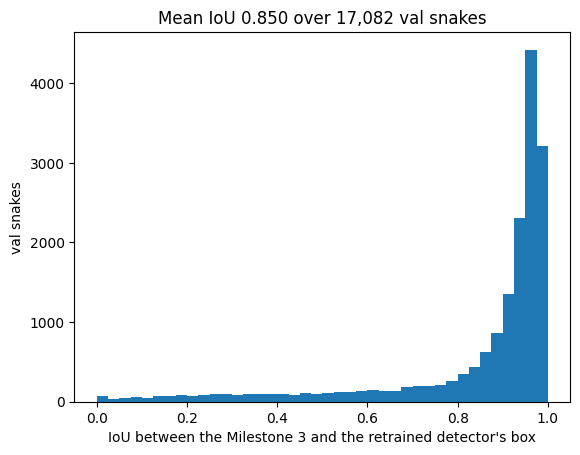

,box agreement
photos,17082.000000
of_val_snakes,17151.000000
mean_iou,0.850473
median_iou,0.941986
share_iou_at_least_0_5,0.908969
share_iou_at_least_0_8,0.793935
box_floor,0.050000


In [19]:
assert FULL_PASSED, "the full pass did not finish"
plt.hist(full.ious, bins=40)
plt.xlabel("IoU between the Milestone 3 and the retrained detector's box"); plt.ylabel("val snakes")
plt.title(f"Mean IoU {full.agreement['mean_iou']:.3f} over {full.agreement['photos']:,} val snakes"); plt.show()
pd.Series(full.agreement).to_frame("box agreement")

**Twenty non-snake validation photos** with the retrained detector's best box (red) and segmenter's mask (green):
the ten it finds most snake-like, then ten at random. The picture is kept in the run's Kaggle output
(`checks/nonsnake_val_sheet.png`) and left out of this notebook, which shows no photos; the credits below are numbered
as the photos are in it, with their categories. Nine of the ten most snake-like photos are lookalikes (caecilians,
glass lizards, earthworms, an eel). Read off the sheet, the nine are boxed at 0.91 to 0.94 and painted
almost whole, and the tenth, a person's photo, is boxed at 0.92 but gets no mask, so the picked gate does
not call it a snake. Of the ten at random, the people, cats, T-shirts and hands get no mask on the sheet;
a caecilian, a glass lizard and a small eel are called snakes. These readings of the sheet are recorded
only here.

In [20]:
assert FULL_PASSED, "the full pass did not finish"
display(Picture(filename=str(full.out / "checks" / "nonsnake_val_sheet.png")))
full.credits

,owner,licence,url,category
photo,,,,
1,salomao_janderson,cc-by,https://www.inaturalist.org/observations/19814...,caecilian
2,kai_pirinha,cc-by,https://www.inaturalist.org/observations/33133...,legless_lizard
3,douglas-u-oliveira,cc-by,https://www.inaturalist.org/observations/78393040,caecilian
4,eduardo_chacon,cc-by,https://www.inaturalist.org/observations/15783...,caecilian
5,quentin_benet_cibois,cc-by,https://www.inaturalist.org/observations/20836...,legless_lizard
6,Dean Jarvey,cc-by-2.0,https://www.flickr.com/photos/28009451@N03/439...,person
7,kartrick,cc-by,https://www.inaturalist.org/observations/12618...,caecilian
8,jarronevsbaru,cc-by,https://www.inaturalist.org/observations/18684...,earthworm
9,taytonalvis,cc-by,https://www.inaturalist.org/observations/13647...,eel


## What we found

**Before.** The Milestone 3 front end calls almost every photo a snake. The reproduction check passed: every snake
photo outside Milestone 3's one-shape calls kept its confidence to within 0.00005, and the box cut-off refitted to
0.1020. At that cut-off the box gate calls 95.3% of the 600 non-snake validation photos a snake; the mask alone
calls 98.7% and both together 96.2%. That includes 92.8% of the people and 96.7% of the T-shirts at the both-must-agree gate.

**After.** Retraining with the non-snake photos cuts the false-snake rate to 39.2% with the box alone, 28.0% with
the mask alone and 27.3% when both must agree. At the picked gate: people 8.3%, T-shirts 3.3%, cats 7.5%, dogs 5.0%,
hands and arms 6.7%, ropes, hoses and belts 25.0%, other animals 41.7%. The lookalikes are still called snakes:
every caecilian, glass lizard and earthworm, and 95% of the eels, 98 of the 100. On the other 500 photos, 66 are
called snakes (13.2%).

**The pick and the 99%.** The non-snake photos pick "both", but its cut-offs are the loosest the fit allows (0.005
for the box, 0.00005 of the photo for the mask), so in effect it means "the segmenter paints anything at all". The
retrained segmenter paints nothing on 2.0% of the calibration snakes, so no gate that needs a mask can keep 99% of
them: "mask" and "both" keep 97.97% of the calibration snakes and find 98.3% of the validation snakes. The box gate
keeps 99.01% of the calibration snakes and finds 98.97% of the validation snakes, at 39.2% false snakes.

**Goal G4 is not met on validation by any gate.** The lowest false-snake rate is 27.3%, more than five times the
5% goal, and no retrained gate finds 99% of the validation snakes. Most of the photos that still fool it are
lookalikes, which look like snakes to people too.

**Snakes that look like the lookalikes.** With the box gate, the retrained detector finds about as many sea snakes
(99.3% against 99.9% before), water snakes, blind snakes and shieldtails, and vine snakes as before. The mask
gates lose the most on sea snakes and sea kraits (96.9%) and on blind snakes and shieldtails (97.4%).

**The new boxes.** On 17,082 validation snakes boxed by both detectors, the boxes overlap by a mean IoU of 0.850
(median 0.942); 90.9% overlap by at least 0.5 and 79.4% by at least 0.8. About one validation snake in eleven
would be cropped quite differently in the app than in full training, which uses the Milestone 3 boxes.